# 0. Timeframe selection

This notebook was used to determine the timeframe for the baseline period. It reproduces an analysis from van Dijk et al. (2021) using the time horizon used in the current study.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import re

# Make sure that all columns are visible when a dataframe is printed
pd.set_option('display.max_columns', None)

## Plot the policy regarding the number of allowed visitors

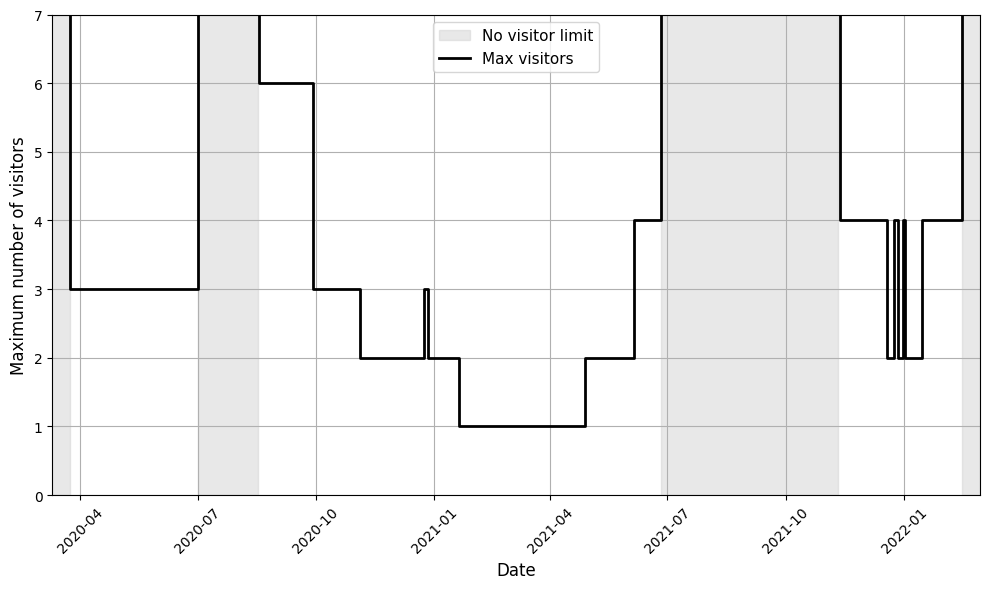

In [15]:
# Get the dataset with the policy regarding the number of allowed visitors
df_measure = pd.read_csv("data/df_measure.csv")
df_measure["date"] = pd.to_datetime(df_measure["Date"])

df_measure["Limit"] = df_measure["Limit"].replace(np.inf, 1000)

# Plot the data as a step plot
plt.figure(figsize=(10, 6))

plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-03-24"), color='lightgray', alpha=0.5) 
plt.axvspan(pd.Timestamp("2020-07-01"), pd.Timestamp("2020-08-17"), color='lightgray', alpha=0.5, label="No visitor limit") 
plt.axvspan(pd.Timestamp("2021-06-26"), pd.Timestamp("2021-11-11"), color='lightgray', alpha=0.5) 
plt.axvspan(pd.Timestamp("2022-02-15"), pd.Timestamp("2022-03-01"), color='lightgray', alpha=0.5) 

plt.step(df_measure["date"], df_measure["Limit"], where="post", label="Max visitors", linewidth=2, color='black')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Maximum number of visitors", fontsize=12)
#plt.title("Maximum number of visitors allowed over time", fontsize=16)
plt.xticks(rotation=45)
plt.legend(loc='upper center', fontsize=11)
plt.grid()
plt.ylim(0, 7)
plt.xlim(pd.Timestamp("2020-03-10"), pd.Timestamp("2022-03-01"))
plt.tight_layout()
plt.savefig("results/visitor_limit.png", dpi=200, bbox_inches='tight')
plt.show()

## Plot the deviation in behavior of individuals who reported a positive test compared to the global mean

Load the COVID-radar data

In [9]:
# Read the raw COVID-radar data
df_radar = pd.read_csv("data/COVID_radar_data/CRdataShared.csv")

# Make sure the date column is a datetime object
df_radar['date'] = pd.to_datetime(df_radar['date'], format='%d%b%Y')

df_radar.head()

,gender,age,profession,contact,cough,sorethroat,fever,shortofbreath,bowelsymptoms,chestsymptoms,eyesymptoms,lossofsmell,fatigue,headache,vaccine,outhousework,outofhouse,numberpersons5m,numbervisitors,numberpersons150cm,numberpersons150cmspoken,mask,public,holiday,brainfog,depressed,date,fatigueExtreme,sport,ID,positivetest,numbertimescovid,firstpositivetest,dayssurroundingpositivetest,everpositive,negativetest,numbernegativetest,firstnegativetest,dayssurroundingnegativetest,evernegativetest,evercovidinapp,evercovidoutapp
0,f,06-11,NaN,0,1,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,1,2,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-05,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
1,f,06-11,NaN,0,1,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,5.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-06,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
2,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,5.0,1,0,5,0,NaN,NaN,NaN,NaN,NaN,2020-04-08,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
3,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-15,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
4,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-05-14,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0


Transform the COVID-radar data to have one row representing a test along with the reported contact counts in the days surrounding that test

In [10]:
# Get unique IDs and dates
unique_ids = df_radar['ID'].unique()
unique_dates = df_radar['date'].unique()

# For all dates, calculate which dates should be in the exposure period if that date is taken as the test date
date_ranges = {
    t0: [(t0 + pd.Timedelta(days=t)) for t in range(-35, 6)] for t0 in unique_dates
}

# Check if the date ranges are correct
# The result is a dictionary with each test date as the key and the dates in the exposure period the values (in a list)
#date_ranges

In [11]:
results = []

# Filter df_radar to only include rows with a test result
df_radar_with_tests = df_radar[(df_radar['positivetest'] == 1) | (df_radar['negativetest'] == 1)]

# Get all dates and IDs from persons who tested
unique_dates = df_radar['date'].unique()
test_ids = df_radar_with_tests['ID'].unique()

# Batch processing was used such that a progress bar could be used
batch_size = 5000

# Loop over all IDs that performed a test in batches
for i in tqdm(range(0, len(test_ids), batch_size)):
    
    # Get the correct IDs and extract all surveys for those IDS
    batch_ids = list(test_ids)[i:i + batch_size]
    batch_data = df_radar[df_radar['ID'].isin(batch_ids)]

    # For each t0 (test) date
    for t0_date in unique_dates:
        
        # Get date range as made in the previous cell (baseline period)
        tf_dates = date_ranges.get(t0_date, [])

        # Get the corresponding surveys that are in the baseline periods
        tf_data = batch_data[batch_data['date'].isin(tf_dates)]

        # Create columns for numbervisitors and numberpersons150cm and fill them with the correct values
        tf_summary = tf_data.pivot_table(
            index="ID",
            columns="date",
            values=["numbervisitors", "numberpersons150cm"]
        )
        tf_summary.columns = [
            f"{col[0]}_T{(col[1] - t0_date).days}" for col in tf_summary.columns
        ]
        tf_summary = tf_summary.reset_index()

        # Add T0_date column
        tf_summary['T0_date'] = t0_date

        # Get all tests performed at the current t0 date
        test_subset = df_radar_with_tests[df_radar_with_tests['date'] == t0_date]
        test_subset = test_subset[['ID', 'positivetest', 'negativetest']].drop_duplicates()
        
        # Merge test results with the correct behavioral data
        merged_summary = test_subset.merge(tf_summary, on='ID', how='left')

        # Append the results for this t0 date
        results.append(merged_summary)

# Concatenate the results of all t0 dates
df_final = pd.concat(results, ignore_index=True)

df_merged2 = pd.merge(df_final, df_radar[['ID', 'date', 'age', 'profession', 'positivetest', 'negativetest']], 
                     left_on=['ID', 'T0_date'], right_on=['ID', 'date'], how='inner')

df_merged2 = df_merged2.drop(columns=['positivetest_y', 'negativetest_y'])

df_merged2.rename(columns={'positivetest_x': 'positivetest', 'negativetest_x': 'negativetest'}, inplace=True)

df_merged2

100%|██████████| 5/5 [01:59<00:00, 23.90s/it]


,ID,positivetest,negativetest,numberpersons150cm_T-2,numberpersons150cm_T-1,numberpersons150cm_T0,numberpersons150cm_T1,numberpersons150cm_T2,numberpersons150cm_T3,numberpersons150cm_T4,numberpersons150cm_T5,numbervisitors_T-2,numbervisitors_T-1,numbervisitors_T0,numbervisitors_T1,numbervisitors_T2,numbervisitors_T3,numbervisitors_T4,numbervisitors_T5,T0_date,numberpersons150cm_T-3,numbervisitors_T-3,numberpersons150cm_T-5,numberpersons150cm_T-4,numbervisitors_T-5,numbervisitors_T-4,numberpersons150cm_T-12,numberpersons150cm_T-11,numberpersons150cm_T-10,numberpersons150cm_T-9,numberpersons150cm_T-8,numberpersons150cm_T-7,numberpersons150cm_T-6,numbervisitors_T-12,numbervisitors_T-11,numbervisitors_T-10,numbervisitors_T-9,numbervisitors_T-8,numbervisitors_T-7,numbervisitors_T-6,numberpersons150cm_T-35,numberpersons150cm_T-34,numberpersons150cm_T-33,numberpersons150cm_T-32,numberpersons150cm_T-31,numberpersons150cm_T-30,numberpersons150cm_T-29,numberpersons150cm_T-28,numberpersons150cm_T-27,numberpersons150cm_T-26,numberpersons150cm_T-25,numberpersons150cm_T-24,numberpersons150cm_T-23,numberpersons150cm_T-22,numberpersons150cm_T-21,numberpersons150cm_T-20,numberpersons150cm_T-19,numberpersons150cm_T-18,numberpersons150cm_T-17,numberpersons150cm_T-16,numberpersons150cm_T-15,numberpersons150cm_T-14,numberpersons150cm_T-13,numbervisitors_T-35,numbervisitors_T-34,numbervisitors_T-33,numbervisitors_T-32,numbervisitors_T-31,numbervisitors_T-30,numbervisitors_T-29,numbervisitors_T-28,numbervisitors_T-27,numbervisitors_T-26,numbervisitors_T-25,numbervisitors_T-24,numbervisitors_T-23,numbervisitors_T-22,numbervisitors_T-21,numbervisitors_T-20,numbervisitors_T-19,numbervisitors_T-18,numbervisitors_T-17,numbervisitors_T-16,numbervisitors_T-15,numbervisitors_T-14,numbervisitors_T-13,date,age,profession
0,48475,1,0,0.0,0.0,1.0,1.0,NaN,0.0,NaN,1.0,0.0,0.0,1.0,1.0,NaN,0.0,NaN,0.0,2020-04-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-05,19-29,NaN
1,20259,1,0,NaN,0.0,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN,NaN,NaN,2020-04-06,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-06,19-29,NaN
2,8072,1,0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,2.0,NaN,0.0,2.0,NaN,NaN,NaN,NaN,2.0,2020-04-08,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,40-49,NaN
3,37377,1,0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,1.0,2020-04-08,0.0,0.0,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,50-59,NaN
4,46069,1,0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,0.0,NaN,NaN,2020-04-08,0.0,0.0,0.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,50-59,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,.

In [12]:
df_frame = df_merged2.copy()

# Filter for the rows where a negative test was reported
negative_tests = df_radar[df_radar['negativetest'] == 1]

# Find the earliest date where a negative test was reported
first_negative_test_date = negative_tests['date'].min()

# Print the earliest date for the negative test
print(f"The first negative test was reported on: {first_negative_test_date}")

# Only select tests occuring after this date from the original data
df_frame = df_frame[df_frame['T0_date'] >= pd.Timestamp("2021-01-01")]

The first negative test was reported on: 2021-01-15 00:00:00


Compare the average behavior of all persons who tested positive from 2021-01-15 on with the average behavior

In [13]:
df_postest = df_frame[
    (df_frame["positivetest"] == 1) & 
    (df_frame["T0_date"] >= pd.Timestamp("2021-01-15"))
]

df_negtest = df_frame[
    (df_frame["negativetest"] == 1) & 
    (df_frame["T0_date"] >= pd.Timestamp("2021-01-15"))
]

# Define column names
persons_columns = sorted(
    [col for col in df_postest.columns if col.startswith("numberpersons150cm_T")],
    key=lambda x: int(x.split("_T")[-1])
)
visitors_columns = sorted(
    [col for col in df_postest.columns if col.startswith("numbervisitors_T")],
    key=lambda x: int(x.split("_T")[-1])
)

# December 11th, as we are taking 35 days before 15-jan-2021 (First date that tests could be reported)
df_frame_radar = df_radar[df_radar['date'] >= pd.Timestamp("2020-12-11")]

# Compute column-wise means
mean_persons = df_frame_radar["numberpersons150cm"].mean(skipna=True)
mean_visitors = df_frame_radar["numbervisitors"].mean(skipna=True)

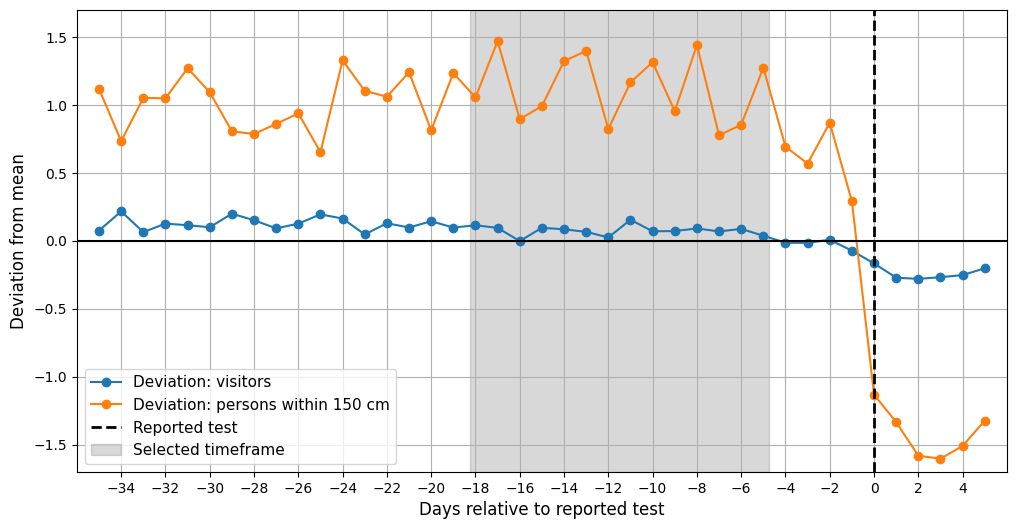

In [14]:
# Extract relative time offsets from column names like 'numberpersons150cm_T-35'
time_offsets = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in persons_columns]

# Sort columns and offsets together to maintain correct order
sorted_columns_with_offsets = sorted(zip(time_offsets, persons_columns), key=lambda x: x[0])
sorted_offsets, sorted_persons_columns = zip(*sorted_columns_with_offsets)

# Do the same for visitors
time_offsets_visitors = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in visitors_columns]
sorted_columns_with_offsets_visitors = sorted(zip(time_offsets_visitors, visitors_columns), key=lambda x: x[0])
_, sorted_visitors_columns = zip(*sorted_columns_with_offsets_visitors)

# Recalculate deviations with sorted columns
diff_persons = df_postest[list(sorted_persons_columns)] - mean_persons
diff_visitors = df_postest[list(sorted_visitors_columns)] - mean_visitors

# Mean deviations
mean_diff_persons = diff_persons.mean(skipna=True)
mean_diff_visitors = diff_visitors.mean(skipna=True)

# Plot using correct time offsets
plt.figure(figsize=(12, 6))

plt.plot(sorted_offsets, mean_diff_visitors, marker='o', linestyle='-', label="Deviation: visitors")
plt.plot(sorted_offsets, mean_diff_persons, marker='o', linestyle='-', label="Deviation: persons within 150 cm")

plt.xlabel("Days relative to reported test", size=12)
plt.ylabel("Deviation from mean", size=12)
#plt.title("Deviation from mean for persons who tested positive", size=16)

# Show every second tick
every_second_tick = [x for i, x in enumerate(sorted_offsets) if i % 2 != 0]
plt.xticks(every_second_tick)

plt.axhline(0, color='black', linestyle='-')
plt.axvline(x=0, color='black', linestyle='--', linewidth=2, label="Reported test")

plt.xlim(-36, 6)
plt.ylim(-1.7, 1.7)

# Highlight the selected timeframe
plt.axvspan(-18.25, -4.75, color='gray', alpha=0.3, label="Selected timeframe")

plt.legend(fontsize=11)
plt.grid()
plt.savefig("results/timeframe_selection.png", dpi=200, bbox_inches='tight')
plt.show()

EXTRA: Also do this for individuals who tested negative

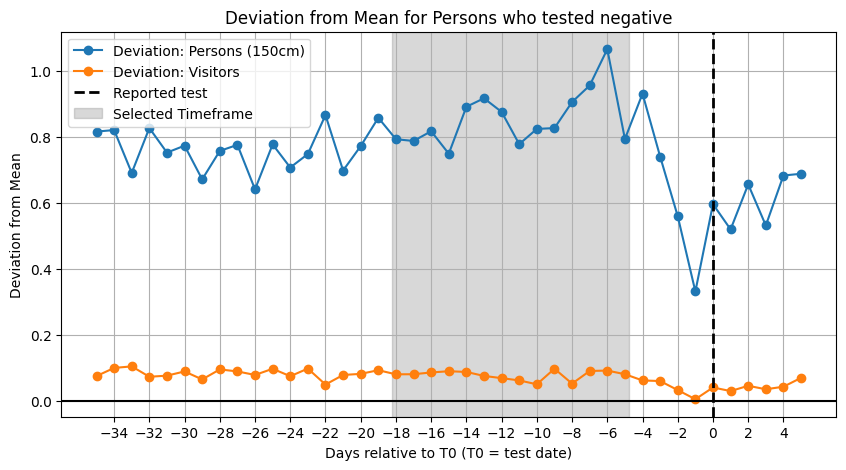

In [ ]:
# Extract relative time offsets from column names like 'numberpersons150cm_T-35'
time_offsets = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in persons_columns]

# Sort columns and offsets together to maintain correct order
sorted_columns_with_offsets = sorted(zip(time_offsets, persons_columns), key=lambda x: x[0])
sorted_offsets, sorted_persons_columns = zip(*sorted_columns_with_offsets)

# Do the same for visitors
time_offsets_visitors = [int(re.search(r"_T(-?\d+)", col).group(1)) for col in visitors_columns]
sorted_columns_with_offsets_visitors = sorted(zip(time_offsets_visitors, visitors_columns), key=lambda x: x[0])
_, sorted_visitors_columns = zip(*sorted_columns_with_offsets_visitors)

# Recalculate deviations with sorted columns
diff_persons = df_negtest[list(sorted_persons_columns)] - mean_persons
diff_visitors = df_negtest[list(sorted_visitors_columns)] - mean_visitors

# Mean deviations
mean_diff_persons = diff_persons.mean(skipna=True)
mean_diff_visitors = diff_visitors.mean(skipna=True)

# Plot using correct time offsets
plt.figure(figsize=(10, 5))

plt.plot(sorted_offsets, mean_diff_persons, marker='o', linestyle='-', label="Deviation: Persons (150cm)")
plt.plot(sorted_offsets, mean_diff_visitors, marker='o', linestyle='-', label="Deviation: Visitors")

plt.xlabel("Days relative to T0 (T0 = test date)")
plt.ylabel("Deviation from Mean")
plt.title("Deviation from Mean for Persons who tested negative")

every_second_tick = [x for i, x in enumerate(sorted_offsets) if i % 2 != 0]
plt.xticks(every_second_tick)

plt.axhline(0, color='black', linestyle='-')
plt.axvline(x=0, color='black', linestyle='--', linewidth=2, label="Reported test")  # T0

# Highlight the selected timeframe
plt.axvspan(-18.25, -4.75, color='gray', alpha=0.3, label="Selected Timeframe")

plt.legend()
plt.grid()
plt.show()